In [12]:
#!/usr/bin/env python3
"""
Convert the GPS track in gps1_raw.csv to UTM and plot it in 2D.

Usage (put this file next to utm.py and gps1_raw.csv):
    python3 gps_to_utm_plot.py
"""
import csv
import matplotlib.pyplot as plt
from utm import utmconv

# read lat/lon
with open('gps1_raw.csv') as f:
    rows = list(csv.DictReader(f))

# convert every point to UTM
uc = utmconv()
easting, northing = [], []
for r in rows:
    hemisphere, zone, letter, e, n = uc.geodetic_to_utm(float(r['lat']), float(r['lon']))
    easting.append(e)
    northing.append(n)
print('Converted %d points to UTM zone %d%s' % (len(rows), zone, letter))


Converted 1754 points to UTM zone 32U


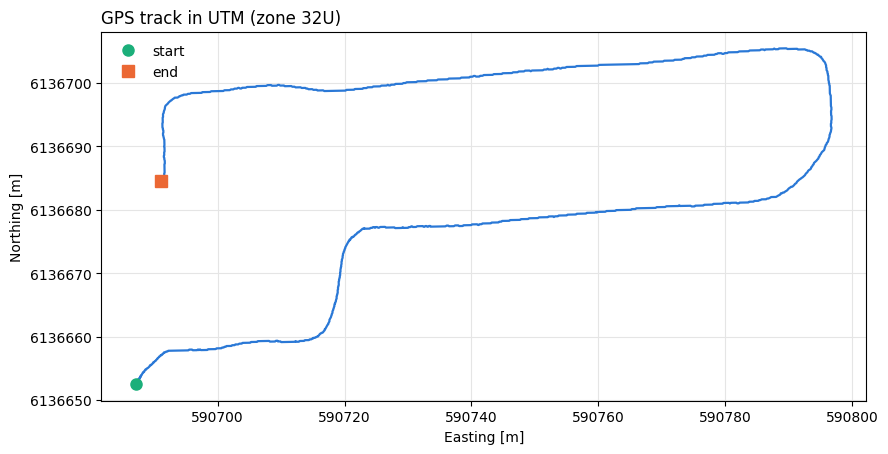

In [13]:

# 2D plot
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(easting, northing, color='#2a78d6', lw=1.6)
ax.plot(easting[0], northing[0], 'o', color='#1baf7a', ms=8, label='start')
ax.plot(easting[-1], northing[-1], 's', color='#eb6834', ms=8, label='end')
ax.set_aspect('equal')                                   # 1 m east = 1 m north
ax.ticklabel_format(useOffset=False, style='plain')
ax.grid(color='#e5e5e5')
ax.set_xlabel('Easting [m]')
ax.set_ylabel('Northing [m]')
ax.set_title('GPS track in UTM (zone %d%s)' % (zone, letter), loc='left')
ax.legend(frameon=False)
fig.tight_layout()
plt.show()